# UK customers: Monthly retention rate

## 1. Load and inspect the data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

%matplotlib inline

In [8]:
df = pd.read_csv("H:\\Training for Interview - PART INC\\Github\\MasterClass-FinTech-01\\session_1\\5.online_retail\\OnlineRetail.csv", encoding='latin1')
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


missing values - CustomerID is the important one here

In [10]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

`CustomerID` has many missing values (guest checkouts). They can't be tracked as a customer from month to month, so they have to go. `InvoiceDate` is stored as text and must be converted to datetime.

## 2. Prepare the UK customer data

UK only, and only rows where we know the customer

In [30]:
df_uk = df[df["Country"] == "United Kingdom"].dropna(subset=["CustomerID"]).copy()
df_uk["CustomerID"] = df_uk["CustomerID"].astype(int)


In [44]:
# Quantity > 0
#df_uk = df[(df["Country"] == "United Kingdom") & (df["Quantity"] > 0)].dropna(subset=["CustomerID"]).copy()

dates look like 12/1/2010 8:26 -> month/day/year

In [34]:
df_uk["InvoiceDate"] = pd.to_datetime(df_uk["InvoiceDate"], format="%m/%d/%Y %H:%M")

year-month column, e.g. 2010-12

In [35]:
df_uk["InvoiceYearMonth"] = df_uk["InvoiceDate"].dt.to_period("M")

In [36]:
print("UK rows with a CustomerID:", df_uk.shape[0])
print("unique UK customers:", df_uk["CustomerID"].nunique())
print("date range:", df_uk["InvoiceDate"].min(), "->", df_uk["InvoiceDate"].max())

UK rows with a CustomerID: 361878
unique UK customers: 3950
date range: 2010-12-01 08:26:00 -> 2011-12-09 12:49:00


rows per month - December 2011 should look much smaller than the other months

In [37]:
df_uk.groupby("InvoiceYearMonth").size()

InvoiceYearMonth
2010-12    24536
2011-01    18738
2011-02    18110
2011-03    24587
2011-04    21358
2011-05    25738
2011-06    24296
2011-07    24170
2011-08    23623
2011-09    36333
2011-10    44621
2011-11    59691
2011-12    16077
Freq: M, dtype: int64

The data ends on 9 December 2011, so December 2011 is incomplete. I keep it in the calculation but leave it out of the final chart.

## 3. Customer-by-month activity table

SQL idea: SELECT CustomerID, month, COUNT(*) ... GROUP BY CustomerID, month
crosstab gives one row per customer, one column per month,
and the number of invoice lines in that month

In [38]:
df_user = pd.crosstab(df_uk["CustomerID"], df_uk["InvoiceYearMonth"])
print(df_user.shape)
df_user.head()

(3950, 13)


InvoiceYearMonth,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
CustomerID,,,,,,,,,,,,,
12346,0,2,0,0,0,0,0,0,0,0,0,0,0
12747,15,5,0,12,0,23,8,0,7,0,15,11,7
12748,670,25,101,211,102,269,262,226,140,416,221,1693,306
12749,0,0,0,0,0,54,0,0,106,0,0,32,39
12820,0,11,0,0,0,0,0,0,0,14,22,0,12


I only care about "active or not", so turn the counts into True/False

In [20]:
active = df_user > 0
active.head()

InvoiceYearMonth,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
CustomerID,,,,,,,,,,,,,
12346,False,True,False,False,False,False,False,False,False,False,False,False,False
12747,True,True,False,True,False,True,True,False,True,False,True,True,True
12748,True,True,True,True,True,True,True,True,True,True,True,True,True
12749,False,False,False,False,False,True,False,False,True,False,False,True,True
12820,False,True,False,False,False,False,False,False,False,True,True,False,True


## 4. Total active customers and retained customers

- **Total active customers** in a month = customers with at least one purchase in that month
- **Retained customers** in a month = customers active in that month **and** in the previous month

The first month (Dec 2010) has no previous month, so it can't have a retention rate.

In [21]:
months = list(active.columns)

rows = []
for i in range(1, len(months)):
    current_month = months[i]
    prev_month = months[i - 1]

    total_active = active[current_month].sum()
    retained = (active[current_month] & active[prev_month]).sum()

    rows.append({
        "month": current_month,
        "total_customers": total_active,
        "retained_customers": retained,
        "retention_rate": retained / total_active,
    })

retention = pd.DataFrame(rows)
retention

,month,total_customers,retained_customers,retention_rate
0,2011-01,684,322,0.470760
1,2011-02,714,263,0.368347
2,2011-03,923,305,0.330444
3,2011-04,817,310,0.379437
4,2011-05,985,369,0.374619
5,2011-06,943,417,0.442206
6,2011-07,899,379,0.421580
7,2011-08,867,391,0.450980
8,2011-09,1177,417,0.354291
9,2011-10,1285,502,0.390661


cross-check with numpy (vectorised version of the same thing)

In [22]:
a = active.values
retained_np = (a[:, 1:] & a[:, :-1]).sum(axis=0)
total_np = a[:, 1:].sum(axis=0)

assert (retained_np == retention["retained_customers"].values).all()
assert (total_np == retention["total_customers"].values).all()
print("loop and numpy results match")

loop and numpy results match


Retention rate here follows the formula from the exercise: retained customers divided by the total active customers **in the same month**.

## 5. Line chart of the monthly retention rate

drop December 2011 (incomplete month)

In [23]:
retention_plot = retention[retention["month"] != pd.Period("2011-12")].copy()
retention_plot["month_label"] = retention_plot["month"].astype(str)

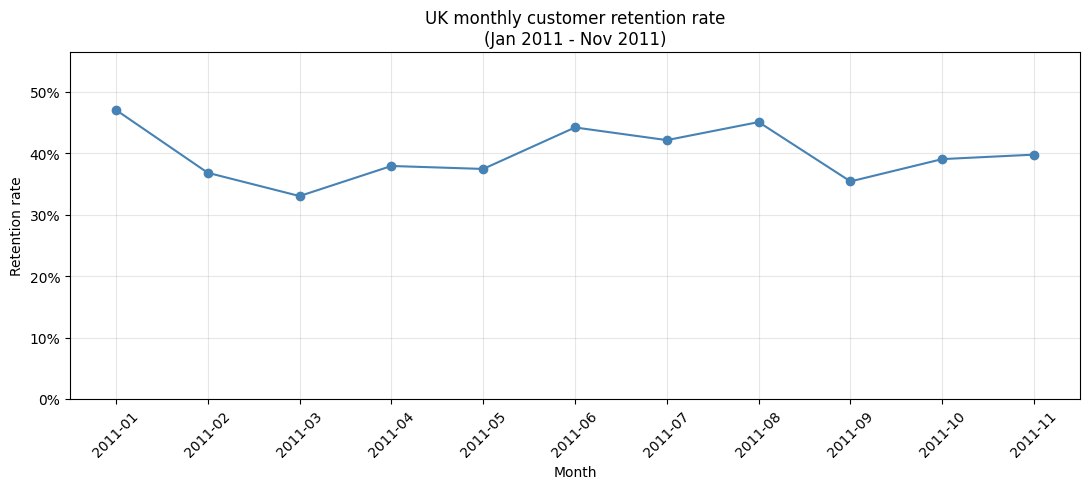

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(retention_plot["month_label"], retention_plot["retention_rate"],
        marker="o", color="steelblue")

ax.set_title("UK monthly customer retention rate\n(Jan 2011 - Nov 2011)")
ax.set_xlabel("Month")
ax.set_ylabel("Retention rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(0, retention_plot["retention_rate"].max() * 1.2)
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

final table used in the chart, with the rate as a percentage

In [25]:
retention_plot[["month_label", "total_customers", "retained_customers", "retention_rate"]] \
    .assign(retention_rate=lambda d: (d["retention_rate"] * 100).round(1))

,month_label,total_customers,retained_customers,retention_rate
0,2011-01,684,322,47.1
1,2011-02,714,263,36.8
2,2011-03,923,305,33.0
3,2011-04,817,310,37.9
4,2011-05,985,369,37.5
5,2011-06,943,417,44.2
6,2011-07,899,379,42.2
7,2011-08,867,391,45.1
8,2011-09,1177,417,35.4
9,2011-10,1285,502,39.1


## 6. Extra check: removing cancelled invoices

Rows with a negative Quantity are mostly cancellations (InvoiceNo starting with C). 
A customer with only a cancellation in a month would still count as "active", so I re-ran the calculation with Quantity > 0 to see if the result changes.

In [39]:
df_uk_pos = df_uk[df_uk["Quantity"] > 0]
print("rows removed:", len(df_uk) - len(df_uk_pos))

rows removed: 7533


In [40]:
active_pos = pd.crosstab(df_uk_pos["CustomerID"], df_uk_pos["InvoiceYearMonth"]) > 0
a2 = active_pos.values

In [41]:
retention_pos = pd.DataFrame({
    "month_label": active_pos.columns[1:].astype(str),
    "total_customers": a2[:, 1:].sum(axis=0),
    "retained_customers": (a2[:, 1:] & a2[:, :-1]).sum(axis=0),
})
retention_pos["retention_rate"] = retention_pos["retained_customers"] / retention_pos["total_customers"]
retention_pos = retention_pos[retention_pos["month_label"] != "2011-12"]

side-by-side comparison with the original result

In [42]:
compare = (retention_plot[["month_label", "retention_rate"]]
           .rename(columns={"retention_rate": "original"})
           .merge(retention_pos[["month_label", "retention_rate"]]
                  .rename(columns={"retention_rate": "quantity_gt_0"}),
                  on="month_label"))
compare

,month_label,original,quantity_gt_0
0,2011-01,0.470760,0.446677
1,2011-02,0.368347,0.343152
2,2011-03,0.330444,0.288636
3,2011-04,0.379437,0.349490
4,2011-05,0.374619,0.353430
5,2011-06,0.442206,0.413948
6,2011-07,0.421580,0.389988
7,2011-08,0.450980,0.424460
8,2011-09,0.354291,0.338569
9,2011-10,0.390661,0.361789


**Takeaway:** The monthly retention rate stays between about 33% and 47% through 2011. 
It is highest in January 2011 (47.1%) and lowest in March 2011 (33.0%). 
The final month (December 2011) is excluded because the data stops on 9 December, which inflates its rate (65.2%).